# Chapitre 4 - Cours 5 : flux de données par les services, REST et RPC

Deuxième mode de flux de données : des processus qui se parlent **directement** par le
réseau, un client envoyant des requêtes à un serveur. Ce cours construit un vrai petit
service HTTP en local pour mesurer ce que coûte un appel distant, montre pourquoi un
appel réseau n'est **pas** un appel de fonction, puis étudie l'évolution des API. Il
couvre la section *Dataflow Through Services: REST and RPC* (*Web services*, *The problems
with remote procedure calls*, *Current directions for RPC*, *Data encoding and evolution for RPC*).

**Plan.**

1. Clients, serveurs et services.
2. Les services web et REST, en vrai sur la machine.
3. Les problèmes des appels de procédure distants : latence, délais, relances.
4. L'évolution des API : qui doit être compatible avec qui ?


In [1]:
import json
import threading
import time
import urllib.error
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle, SEQ)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Clients, serveurs et services (section *Dataflow Through Services: REST and RPC*)

La façon la plus courante de faire communiquer des processus par le réseau distingue deux
rôles : des **serveurs** exposent une API, des **clients** s'y connectent pour faire des
requêtes. L'API exposée s'appelle un **service**. Le web fonctionne ainsi : le navigateur
envoie des requêtes `GET` (pages, images, scripts) et `POST` (formulaires) à des serveurs,
selon des standards communs (HTTP, URL, TLS, HTML). Les applications mobiles et le
JavaScript exécuté dans le navigateur font aussi des requêtes HTTP, mais reçoivent des
**données** (souvent du JSON) plutôt que du HTML à afficher.

Un service ressemble à une base (on y soumet et on y interroge des données), avec une
différence : une base accepte des requêtes arbitraires dans un langage de requête, un
service n'expose qu'une API **prédéfinie** par sa logique métier. Cette restriction est
une **encapsulation** : le service contrôle finement ce que les clients peuvent faire.

Une architecture orientée services (ou **microservices**) vise à rendre l'application
plus facile à faire évoluer, en rendant chaque service **déployable indépendamment** par
l'équipe qui le possède, sans coordination avec les autres. Il faut donc s'attendre à ce
que d'anciennes et de nouvelles versions de serveurs et de clients tournent en même temps.

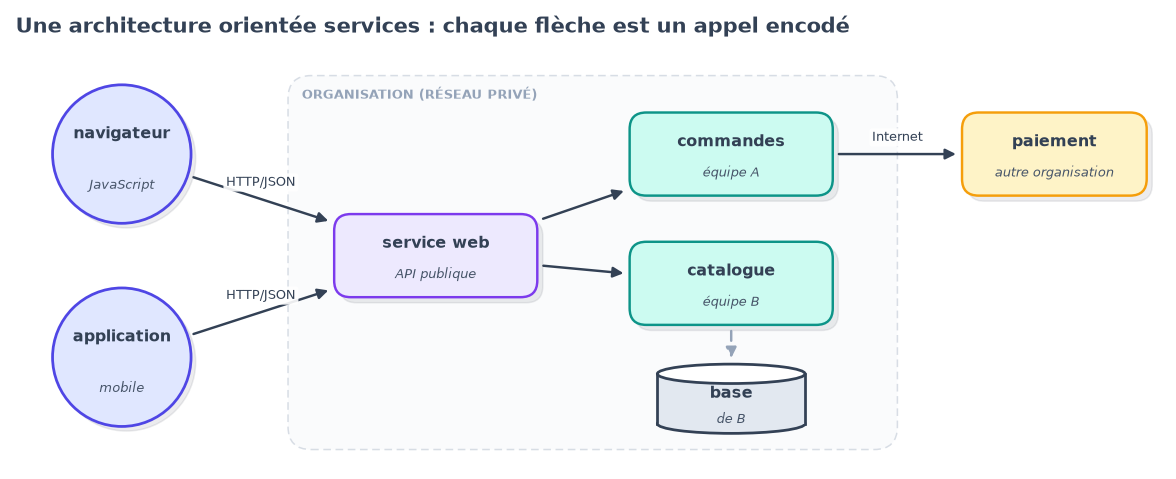

In [2]:
d = Diagram(12.5, 4.4, title="Une architecture orientée services : chaque flèche est un appel encodé")
d.box("nav", 1.2, 3.4, "navigateur", sub="JavaScript", color=INDIGO, kind="user", w=1.5)
d.box("mob", 1.2, 1.2, "application", sub="mobile", color=INDIGO, kind="user", w=1.5)
d.group(3.0, 0.2, 9.6, 4.25, "organisation (réseau privé)", color=GRAY)
d.box("web", 4.6, 2.3, "service web", sub="API publique", color=VIOLET, w=2.2)
d.box("cmd", 7.8, 3.4, "commandes", sub="équipe A", color=TEAL, w=2.2)
d.box("cat", 7.8, 2.0, "catalogue", sub="équipe B", color=TEAL, w=2.2)
d.box("db1", 7.8, 0.75, "base", sub="de B", color=SLATE, kind="db", w=1.6, h=0.75)
d.box("pay", 11.3, 3.4, "paiement", sub="autre organisation", color=AMBER, w=2.0)
d.arrow("nav", "web", "HTTP/JSON")
d.arrow("mob", "web", "HTTP/JSON")
d.arrow("web", "cmd")
d.arrow("web", "cat")
d.arrow("cat", "db1", style="dashed", color=GRAY)
d.arrow("cmd", "pay", "Internet")
d.show()

> **À retenir.** Un service expose une API prédéfinie par le réseau ; le client encode la
> requête, le serveur la décode, encode la réponse, et le client la décode. Les services
> sont déployés indépendamment : versions anciennes et nouvelles coexistent.

## 2. Les services web et REST (section *Web services*)

On parle de **service web** quand le protocole sous-jacent est HTTP, même hors du web :
une application mobile qui appelle un serveur par Internet, deux services d'une même
organisation dans un réseau privé, ou deux organisations qui échangent des données (API
publiques de paiement, OAuth pour partager l'accès à des données).

La philosophie la plus répandue est **REST**, qui s'appuie sur les principes de HTTP :
des formats de données simples, des URL pour identifier des **ressources**, et les
mécanismes de HTTP pour le cache, l'authentification et la négociation du type de
contenu. Construisons un vrai petit service REST avec la bibliothèque standard : une
ressource `/clients/<id>` (lecture `GET`, écriture `PUT`) et une ressource `/paiements`
(`POST`), qui tourne dans un fil d'exécution sur la boucle locale de la machine.

Le livre oppose REST à **SOAP**, un protocole fondé sur XML qui cherche à être
indépendant de HTTP et s'accompagne d'une pile complexe de normes (WS-*). Une API SOAP se
décrit dans un langage XML, WSDL, qui permet de générer le code client ; mais les
messages sont trop complexes pour être écrits à la main, l'interopérabilité entre
fournisseurs est souvent décevante, et SOAP a reculé au profit de REST hors des grandes
entreprises. Pour décrire une API REST, on peut utiliser un format comme OpenAPI (aussi
appelé Swagger), qui produit la documentation.

In [3]:
class Etat:
    clients = {1: {"id": 1, "nom": "Ana", "ville": "Lyon"}}
    paiements = []            # effets de bord réels (débits)
    deja_vus = {}             # clé d'idempotence -> réponse mémorisée
    en_cours = set()          # clés réservées dont le traitement n'est pas fini
    reserver = False          # réserver la clé dès la réception ?
    lenteur = 0.0             # délai artificiel du prochain paiement (secondes)
    verrou = threading.Lock()

class Handler(BaseHTTPRequestHandler):
    def log_message(self, *args):          # silence
        pass

    def _repondre(self, code, obj):
        corps = json.dumps(obj).encode()
        self.send_response(code)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(corps)))
        self.end_headers()
        try:
            self.wfile.write(corps)
        except BrokenPipeError:            # le client a abandonné : la réponse se perd
            pass

    def do_GET(self):
        if self.path == "/ping":
            return self._repondre(200, {"message": "pong"})
        if self.path.startswith("/clients/"):
            c = Etat.clients.get(int(self.path.split("/")[2]))
            return self._repondre(200, c) if c else self._repondre(404, {"erreur": "inconnu"})
        self._repondre(404, {"erreur": "ressource inconnue"})

    def do_PUT(self):
        cid = int(self.path.split("/")[2])
        doc = json.loads(self.rfile.read(int(self.headers["Content-Length"])))
        Etat.clients[cid] = {**doc, "id": cid}
        self._repondre(200, Etat.clients[cid])

    def do_POST(self):
        doc = json.loads(self.rfile.read(int(self.headers["Content-Length"])))
        cle = self.headers.get("Idempotency-Key")
        with Etat.verrou:
            if cle and cle in Etat.deja_vus:
                return self._repondre(200, Etat.deja_vus[cle])
            if cle and Etat.reserver:
                if cle in Etat.en_cours:                 # doublon pendant le traitement
                    return self._repondre(409, {"erreur": "traitement en cours, réessayez"})
                Etat.en_cours.add(cle)
            lent, Etat.lenteur = Etat.lenteur, 0.0
        time.sleep(lent)                           # serveur momentanément lent
        with Etat.verrou:
            Etat.paiements.append(doc["montant"])
            rep = {"paiement": len(Etat.paiements), "montant": doc["montant"]}
            if cle:
                Etat.deja_vus[cle] = rep
                Etat.en_cours.discard(cle)
        self._repondre(201, rep)

ThreadingHTTPServer.request_queue_size = 128                     # file de connexions en attente
serveur = ThreadingHTTPServer(("127.0.0.1", 0), Handler)       # port choisi par le système
threading.Thread(target=serveur.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{serveur.server_address[1]}"

def appel(methode, chemin, corps=None, timeout=2.0, entetes=None):
    data = json.dumps(corps).encode() if corps is not None else None
    req = urllib.request.Request(BASE + chemin, data=data, method=methode,
                                 headers={"Content-Type": "application/json", **(entetes or {})})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.status, json.loads(r.read())

print(appel("GET", "/clients/1"))
print(appel("PUT", "/clients/2", {"nom": "Bob", "ville": "Lille"}))
print(appel("GET", "/clients/2"))

(200, {'id': 1, 'nom': 'Ana', 'ville': 'Lyon'})
(200, {'nom': 'Bob', 'ville': 'Lille', 'id': 2})
(200, {'nom': 'Bob', 'ville': 'Lille', 'id': 2})


Le client encode un document JSON, l'envoie dans une requête HTTP ; le serveur le décode,
applique sa logique, encode la réponse. Les deux côtés doivent s'accorder sur les URL,
les méthodes et le format des documents : c'est le **contrat** de l'API.

> **À retenir.** REST utilise HTTP tel quel : ressources désignées par des URL, méthodes
> HTTP, formats simples (JSON). Une description formelle de l'API sert de contrat, de
> documentation et de base à la génération de code.

## 3. Les problèmes des appels de procédure distants (section *The problems with remote procedure calls*)

Les services web ne sont que la dernière incarnation d'une longue lignée de technologies
d'appel à distance : Enterprise JavaBeans et RMI (limités à Java), DCOM (limité aux
plateformes Microsoft), CORBA (excessivement complexe, sans compatibilité ascendante ni
descendante), SOAP et les normes WS-* (complexité et interopérabilité décevante). Toutes
reposent sur l'idée de l'**appel de procédure distant** (RPC, années 1970) : faire
ressembler une requête réseau à un appel de fonction local. Cette **transparence de
localisation** séduit, mais elle est fondamentalement trompeuse. Le livre liste six
différences ; mesurons les principales.

### Une latence mille fois plus grande, et variable

Un appel de fonction prend à peu près toujours le même temps. Un appel réseau est bien
plus lent, et sa latence varie énormément. Comparons, sur cette machine, un appel de
fonction Python et un vrai appel HTTP sur la boucle locale (sans aucun réseau physique !).

In [4]:
def ping_local():
    return {"message": "pong"}

n_loc = 200_000
t = time.perf_counter()
for _ in range(n_loc):
    ping_local()
local_ns = (time.perf_counter() - t) / n_loc * 1e9

lat = []
for _ in range(1500):
    t = time.perf_counter()
    appel("GET", "/ping")
    lat.append(time.perf_counter() - t)
lat_us = np.array(lat) * 1e6
# un réseau de centre de données réaliste, simulé : 0,5 ms de base, queue log-normale
dc_us = 500 + rng.lognormal(np.log(200), 1.0, 1500) + (rng.random(1500) < 0.01) * 200_000
rapport = f"{np.median(lat_us) * 1e3 / local_ns:,.0f}".replace(",", " ")
print(f"appel local : {local_ns:.0f} ns ; HTTP boucle locale : médiane {np.median(lat_us):.0f} µs, "
      f"p99 {np.percentile(lat_us, 99):.0f} µs (rapport ~{rapport})")

appel local : 44 ns ; HTTP boucle locale : médiane 242 µs, p99 363 µs (rapport ~5 494)


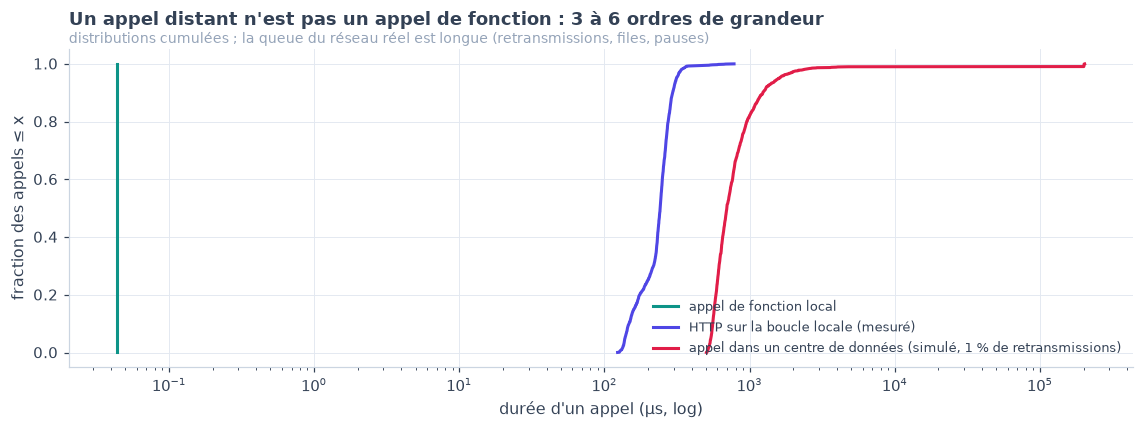

In [5]:
fig, ax = plt.subplots(figsize=(10.5, 4))
for donnees, c, nom in [(np.full(1000, local_ns / 1e3), TEAL, "appel de fonction local"),
                        (lat_us, INDIGO, "HTTP sur la boucle locale (mesuré)"),
                        (dc_us, ROSE, "appel dans un centre de données (simulé, 1 % de retransmissions)")]:
    x = np.sort(donnees)
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=c, label=nom, lw=2)
ax.set_xscale("log"); ax.set_xlabel("durée d'un appel (µs, log)"); ax.set_ylabel("fraction des appels ≤ x")
ax.set_title("Un appel distant n'est pas un appel de fonction : 3 à 6 ordres de grandeur")
subtitle(ax, "distributions cumulées ; la queue du réseau réel est longue (retransmissions, files, pauses)")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

Même sans réseau, l'appel HTTP local coûte quelques centaines de microsecondes : des
milliers de fois un appel de fonction (encodage JSON, pile TCP, analyse HTTP, changement
de fil). Sur un vrai réseau s'ajoutent la propagation et surtout une **queue** de
distribution : en temps normal moins d'une milliseconde, mais quand le réseau est
congestionné ou le service surchargé, la même opération peut prendre des secondes.

### Un résultat inconnu : le délai d'expiration

Un appel local renvoie un résultat, lève une exception, ou ne revient jamais (boucle
infinie, plantage). Un appel réseau a une **quatrième issue** : le délai d'expiration
(timeout) sans réponse. Et dans ce cas, **on ne sait pas ce qui s'est passé**. Les trois
scénarios ci-dessous sont indiscernables pour le client.

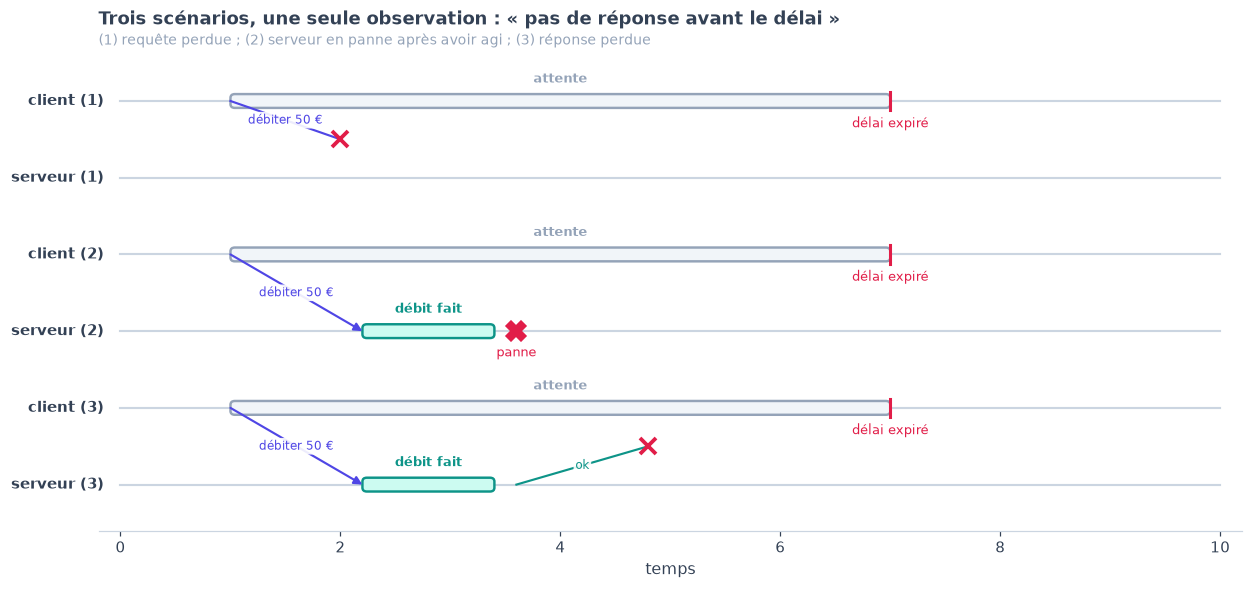

In [6]:
st = SpaceTime(["client (1)", "serveur (1)", "client (2)", "serveur (2)", "client (3)", "serveur (3)"],
               t_max=10, width=11.5, lane_height=0.8,
               title="Trois scénarios, une seule observation : « pas de réponse avant le délai »",
               subtitle="(1) requête perdue ; (2) serveur en panne après avoir agi ; (3) réponse perdue")
for k in (1, 2, 3):
    st.op(f"client ({k})", 1, 7, "attente", color=GRAY)
    st.event(f"client ({k})", 7, "délai expiré", kind="tick", color=ROSE)
st.msg("client (1)", 1, "serveur (1)", 3, "débiter 50 €", color=INDIGO, lost=True)
st.msg("client (2)", 1, "serveur (2)", 2.2, "débiter 50 €", color=INDIGO)
st.op("serveur (2)", 2.2, 3.4, "débit fait", color=TEAL)
st.event("serveur (2)", 3.6, "panne", kind="crash")
st.msg("client (3)", 1, "serveur (3)", 2.2, "débiter 50 €", color=INDIGO)
st.op("serveur (3)", 2.2, 3.4, "débit fait", color=TEAL)
st.msg("serveur (3)", 3.6, "client (3)", 6.0, "ok", color=TEAL, lost=True)
st.show()

Dans le cas 1, il faut relancer ; dans les cas 2 et 3, relancer **débite deux fois**. Le
chapitre 8 reviendra longuement sur cette incertitude.

### Relancer sans dupliquer : l'idempotence

Si l'on relance une requête dont seule la réponse s'est perdue, l'action est exécutée
plusieurs fois, à moins que le protocole n'intègre un mécanisme de **déduplication**
(idempotence, chapitre 11). Notre serveur l'implémente : un client peut joindre
un en-tête `Idempotency-Key` ; le serveur mémorise la réponse associée à chaque clé et la
renvoie sans réexécuter. Provoquons le cas 3 pour de vrai : le serveur met 0,3 s à
traiter le premier paiement, le client abandonne au bout de 0,1 s et relance.

In [7]:
def payer(montant, cle=None, essais=5, timeout=0.1):
    entetes = {"Idempotency-Key": cle} if cle else {}
    for k in range(essais):
        try:
            return k + 1, appel("POST", "/paiements", {"montant": montant}, timeout=timeout, entetes=entetes)
        except urllib.error.HTTPError as exc:            # 409 : en cours, on patiente
            if exc.code == 409:
                time.sleep(0.15)
                continue
            raise
        except (TimeoutError, urllib.error.URLError):
            continue
    return essais, None

resultats = {}
for nom, cle, reserver in [("sans clé", None, False), ("clé, mémorisée en fin de traitement", "commande-42", False),
                           ("clé, réservée dès la réception", "commande-43", True)]:
    Etat.paiements.clear(); Etat.deja_vus.clear(); Etat.en_cours.clear()
    Etat.reserver = reserver
    Etat.lenteur = 0.3                                   # le premier traitement sera lent
    essais, rep = payer(50, cle=cle)
    time.sleep(0.4)                                      # laisse finir le traitement lent
    resultats[nom] = {"tentatives du client": essais, "réponse finale": rep,
                      "débits réellement effectués": len(Etat.paiements)}
pd.DataFrame(resultats).T

,tentatives du client,réponse finale,débits réellement effectués
sans clé,2,"(201, {'paiement': 1, 'montant': 50})",2
"clé, mémorisée en fin de traitement",2,"(201, {'paiement': 1, 'montant': 50})",2
"clé, réservée dès la réception",4,"(200, {'paiement': 1, 'montant': 50})",1


Sans clé, le client a reçu une seule confirmation mais **deux débits** ont eu lieu : le
premier, lent, a fini après l'abandon du client. Avec une clé mémorisée seulement en fin
de traitement, même résultat : la relance arrive **pendant** le traitement lent, quand la
clé n'est pas encore connue. Il faut **réserver** la clé dès la réception : le doublon
reçoit alors « en cours, réessayez » (code 409), et la tentative suivante obtient la
réponse mémorisée. Un seul débit. L'idempotence est un protocole entier, pas un simple
cache de réponses.

Pour quantifier le risque à grande échelle, le module simule 50 000 paiements avec des
pertes de requêtes et de réponses (`E.simulate_retries`), selon le nombre maximal de
tentatives et la présence de déduplication.

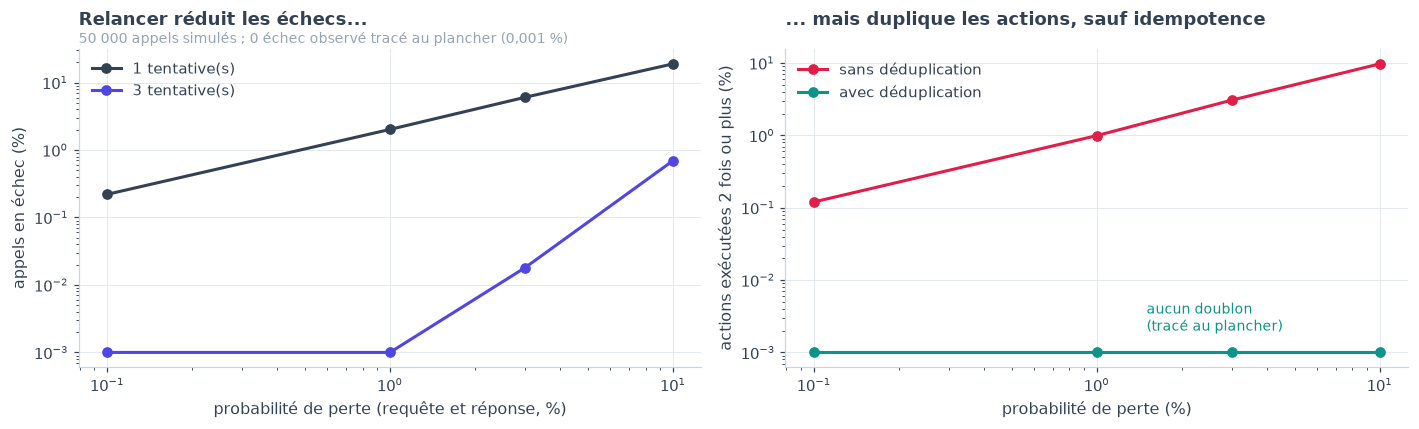

In [8]:
rows = []
for p in [0.001, 0.01, 0.03, 0.1]:
    for tent in (1, 3):
        for idem in (False, True):
            r = E.simulate_retries(50_000, p, p, max_attempts=tent, idempotent=idem, seed=1)
            rows.append({"perte": p, "tentatives": tent, "dédup.": idem, **r})
sim = pd.DataFrame(rows)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for tent, c in [(1, SLATE), (3, INDIGO)]:
    s = sim[(sim.tentatives == tent) & (~sim["dédup."])]
    ax.loglog(s.perte * 100, (1 - s["succès"]).clip(lower=1e-5) * 100, "o-", color=c, label=f"{tent} tentative(s)")
ax.set_xlabel("probabilité de perte (requête et réponse, %)"); ax.set_ylabel("appels en échec (%)")
ax.set_title("Relancer réduit les échecs...")
subtitle(ax, "50 000 appels simulés ; 0 échec observé tracé au plancher (0,001 %)")
ax.legend()
for idem, c in [(False, ROSE), (True, TEAL)]:
    s = sim[(sim.tentatives == 3) & (sim["dédup."] == idem)]
    y = s["exécutée 2 fois ou plus"].clip(lower=1e-5) * 100
    ax2.loglog(s.perte * 100, y, "o-", color=c, label="avec déduplication" if idem else "sans déduplication")
ax2.set_xlabel("probabilité de perte (%)"); ax2.set_ylabel("actions exécutées 2 fois ou plus (%)")
ax2.set_title("... mais duplique les actions, sauf idempotence")
ax2.text(1.5, 2e-3, "aucun doublon\n(tracé au plancher)", color=TEAL, fontsize=9)
ax2.legend(loc="upper left")
plt.tight_layout(); plt.show()

Avec 1 % de pertes, trois tentatives font passer les échecs d'environ 2 % à moins d'un sur
cent mille (aucun sur 50 000) ; mais environ 1 % des paiements sont alors exécutés deux
fois, et près de 10 % avec 10 % de pertes. Seule
l'idempotence côté serveur rend les relances sûres.

### Les trois autres différences

- **Passer des références** : un appel local passe un pointeur, en temps constant. Un
  appel distant doit **encoder** tous les paramètres ; facile pour des nombres ou de
  courtes chaînes, problématique pour de gros objets ou des objets mutables (le serveur
  travaille sur une copie). Le coût croît avec la taille :

In [9]:
tailles = [10, 100, 1_000, 10_000, 100_000]
cout = []
for n in tailles:
    obj = [{"id": i, "nom": f"x{i}", "tags": ["a", "b"]} for i in range(n)]
    t = time.perf_counter()
    for _ in range(3):
        json.loads(json.dumps(obj))
    cout.append((time.perf_counter() - t) / 3 * 1e3)
pd.DataFrame({"éléments": tailles, "encoder + décoder en JSON (ms)": np.round(cout, 3),
              "passer une référence locale": "≈ 0,00005 ms"})

,éléments,encoder + décoder en JSON (ms),passer une référence locale
0,10,0.011,"≈ 0,00005 ms"
1,100,0.046,"≈ 0,00005 ms"
2,1000,0.421,"≈ 0,00005 ms"
3,10000,4.547,"≈ 0,00005 ms"
4,100000,54.244,"≈ 0,00005 ms"


- **Traduire les types** entre langages : client et serveur peuvent être écrits dans des
  langages différents, dont les types ne coïncident pas (souvenez-vous des entiers
  au-delà de $2^{53}$ en JavaScript, cours 1).
- **Le temps d'exécution** imprévisible complique tout le reste (délais d'expiration,
  débit), comme on l'a vu.

Conclusion du livre : inutile de chercher à faire ressembler un service distant à un
objet local, c'est une chose fondamentalement différente. Une partie de l'attrait de REST
vient justement de ce qu'il traite le transfert d'état par le réseau comme un processus
distinct d'un appel de fonction.

### Les orientations actuelles des RPC (section *Current directions for RPC*)

Malgré ces problèmes, les RPC ne disparaissent pas. Plusieurs frameworks s'appuient sur
les encodages du cours 2 et 3 : Thrift et Avro ont leur propre RPC, gRPC utilise Protocol
Buffers, Finagle utilise Thrift, Rest.li du JSON sur HTTP. Cette nouvelle génération
assume que l'appel est distant : Finagle et Rest.li utilisent des **futures** (promesses)
pour encapsuler une action asynchrone qui peut échouer, et facilitent les appels en
parallèle ; gRPC gère des **flux** (une suite de requêtes et de réponses dans la durée) ;
certains frameworks offrent la **découverte de services** (trouver l'adresse IP et le
port d'un service). Mesurons l'intérêt des appels en parallèle : 8 appels à un service
qui met 50 ms à répondre, en séquence puis avec des futures.

In [10]:
def lent(_):
    Etat.lenteur = 0.0
    time.sleep(0.05)                   # attente simulée côté client d'un service lent
    return appel("GET", "/ping")

t = time.perf_counter()
for i in range(8):
    lent(i)
seq = time.perf_counter() - t
t = time.perf_counter()
with ThreadPoolExecutor(max_workers=8) as pool:
    futures = [pool.submit(lent, i) for i in range(8)]
    _ = [f.result() for f in futures]
par = time.perf_counter() - t
print(f"8 appels en séquence : {seq * 1e3:.0f} ms ; avec des futures en parallèle : {par * 1e3:.0f} ms")

8 appels en séquence : 412 ms ; avec des futures en parallèle : 56 ms


Les appels indépendants se recouvrent : la durée totale tombe de 8 fois 50 ms à un peu
plus de 50 ms. Les protocoles binaires des frameworks RPC sont plus performants que du
JSON sur REST ; mais REST garde l'avantage pour les API publiques : on l'essaie avec un
simple navigateur ou `curl`, il marche sur tous les langages et plateformes, et dispose
d'un vaste écosystème d'outils (serveurs, caches, équilibreurs, mandataires, pare-feu).
Les RPC servent surtout entre services d'une même organisation, souvent dans un même
centre de données.

> **À retenir.** Un appel réseau diffère d'un appel local : latence bien plus grande et
> variable, issue inconnue en cas de délai expiré, relances qui dupliquent les actions
> sans idempotence, paramètres à encoder, types à traduire. Mieux vaut l'assumer que le
> cacher derrière une transparence de localisation.